SMS SPAM DETECTION

In [1]:
import sys
print("python version:",sys.version)
try:
    import pandas as pd
    import sklearn
    import matplotlib.pyplot as plt
    print("pandas:",pd.__version__)
    print("scikit-learn",sklearn.__version__)
    print("matplotlib:",plt.matplotlib.__version__)
    print("everything is ready.Let's build!")
except ImportError as e:
    print("a library is missing:",e)

python version: 3.12.13 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:26:47) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.3
scikit-learn 1.9.0
matplotlib: 3.11.0
everything is ready.Let's build!


In [4]:
import os
print("jupyter is looking in:")
print(os.getcwd())
print("\nfiles in the folder:")
print(os.listdir())

jupyter is looking in:
C:\Users\user\Desktop\few_proj

files in the folder:
['.ipynb_checkpoints', 'sms+spam+collection.zip', 'sms_spam_detection.ipynb']


In [7]:
import pandas as pd

df = pd.read_csv(
    "sms_dataset\SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)


<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:4: SyntaxWarning: invalid escape sequence '\S'
C:\Users\user\AppData\Local\Temp\ipykernel_12472\1288261999.py:4: SyntaxWarning: invalid escape sequence '\S'
  "sms_dataset\SMSSpamCollection",


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Count each type of message
print("\nMessage distribution:")
print(df["label"].value_counts())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5572, 2)

Message distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

Accuracy: 96.05 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



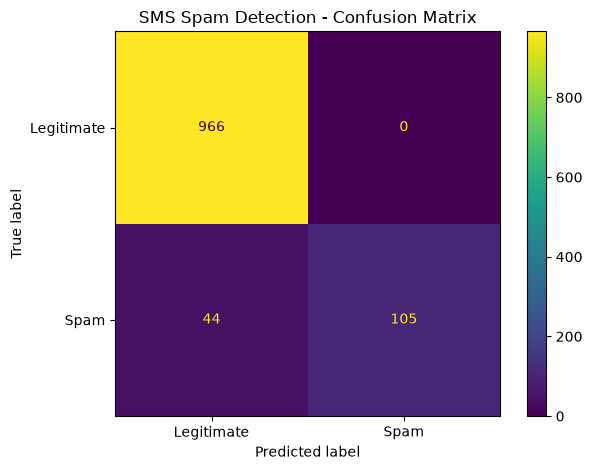

In [10]:
# Separate the messages (input) and their labels (output)
X = df["message"]
y = df["label"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a pipeline that converts text into features and trains a model
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

# Predict labels for unseen test messages
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    display_labels=["Legitimate", "Spam"]
)

plt.title("SMS Spam Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
# Try the trained model on new messages
messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash reward. Call now!"
]

predictions = model.predict(messages)

for message, prediction in zip(messages, predictions):
    result = "SPAM" if prediction == "spam" else "LEGITIMATE"
    print(f"Message: {message}")
    print(f"Prediction: {result}")
    print("-" * 60)

Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: LEGITIMATE
------------------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
------------------------------------------------------------


In [14]:
# Test the trained model with a custom SMS message

message = input("Enter an SMS message: ")

prediction = model.predict([message])[0]

if prediction == "spam":
    print("Prediction: SPAM")
else:
    print("Prediction: LEGITIMATE (HAM)")

Enter an SMS message:  good morning aaj weather report ke hisab se there is 65% chance of precipitation


Prediction: LEGITIMATE (HAM)
